# 02. Eksplorasi Data (EDA)

Analisis statistik deskriptif, missing values, outlier, dan 6 grafik visualisasi eksploratif.

**Prasyarat:** Tahap 01 selesai.

**Keluaran:** Grafik dan laporan statistik di `Source_Code/reports/eda/`.

Pilih kernel Python 3.12 dengan dependency proyek, lalu **Restart Kernel → Run All**. Tahap 01–05 dijalankan secara berurutan. Proyek edukasi data science, bukan diagnosis medis klinis.


## A. Inisialisasi Lingkungan dan Lokasi Proyek
Mempersiapkan konstanta fitur dan folder kerja.


In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
from datetime import datetime, timezone
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'Dataset/Data_Asli/nhanes_depression_raw.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Buka notebook dari dalam folder proyek lengkap dengan Dataset.')
TARGET = "Depression"
LABELS = ["Not Depressed", "Depressed"]
DISPLAY = {
    "Not Depressed": "Tidak Terindikasi Depresi Mayor",
    "Depressed": "Berisiko Mengalami Depresi (PHQ-9 ≥ 10)"
}

CATEGORICAL = [
    "Gender", "Education Level", "Marital Status", "Household Income",
    "Trouble Sleeping History", "Vigorous Recreation", "Moderate Recreation",
    "Current Smoker", "Memory Problems", "Cant Work", "Limited Work"
]
NUMERIC = [
    "Age", "Sleep Hours", "Sedentary Time", "BMI", "Systolic", "Diastolic", "Pulse"
]
FEATURES = CATEGORICAL + NUMERIC

RANGES = {
    "Age": (18, 120),
    "Sleep Hours": (1.0, 24.0),
    "Sedentary Time": (0.0, 1440.0),
    "BMI": (10.0, 90.0),
    "Systolic": (60.0, 260.0),
    "Diastolic": (30.0, 160.0),
    "Pulse": (30.0, 220.0),
}

SEED = 42
REPORTS = ROOT / "Source_Code/reports"
EDA = REPORTS / "eda"
MODELING = REPORTS / "modeling"
ANALYSIS = REPORTS / "analysis"
PROCESSED = ROOT / "Dataset/Data_Olahan"
MODELS = ROOT / "Model"


for folder in [EDA, MODELING, ANALYSIS, PROCESSED, MODELS]:
    folder.mkdir(parents=True, exist_ok=True)
source = ROOT / 'Dataset/Data_Asli/nhanes_depression_raw.csv'
def save_json(path, value):
    path.write_text(
        json.dumps(value, indent=2, ensure_ascii=False,
                   default=lambda x: x.item() if isinstance(x, np.generic) else str(x)),
        encoding="utf-8"
    )

def save_figure(path):
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches='tight')
    display(Image(filename=str(path)))
    plt.close()

print('Proyek:', ROOT)


Proyek: D:\KULIAH\sem-5\MACHINE LEARNING\PJBL\prediksi_gangguan_depresi


## B. Memuat Data dari Tahap 01
Memuat data bersih dan indeks train-test.


In [2]:
split_file = PROCESSED / 'notebook_split.json'
if not split_file.exists():
    raise FileNotFoundError('Jalankan 01_persiapan_data.ipynb terlebih dahulu.')
split_state = json.loads(split_file.read_text(encoding='utf-8'))
for relative, expected in split_state['input_hashes'].items():
    if hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() != expected:
        raise ValueError('Data berubah. Jalankan ulang notebook 01: ' + relative)
raw = pd.read_csv(source, low_memory=False)
saved_clean = pd.read_csv(PROCESSED / 'cleaned.csv', low_memory=False)
clean = saved_clean[FEATURES + [TARGET]].copy()
ids = saved_clean['source_seqn']
profile_hashes = saved_clean['profile_hash'] if 'profile_hash' in saved_clean.columns else pd.util.hash_pandas_object(clean[FEATURES], index=False).astype(str)
conflict_hashes = set()
duplicate_mask = pd.Series([False] * len(raw))
X, y = clean[FEATURES], clean[TARGET]
train_idx, test_idx = split_state['train_indices'], split_state['test_indices']
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
print('Data Latih:', X_train.shape, '| Data Uji:', X_test.shape)


Data Latih: (29007, 18) | Data Uji: (7252, 18)


## C. Statistik Deskriptif dan Deteksi Outlier (IQR)
Statistik outlier dihitung hanya pada data latih.


In [3]:
# Laporan EDA dan Kualitas Data
raw.describe(include="all").to_csv(EDA / "descriptive_raw.csv")
clean.describe(include="all").to_csv(EDA / "descriptive_cleaned.csv")

quality = []
for col in raw.columns:
    quality.append({
        "feature": col,
        "dtype": str(raw[col].dtype),
        "missing_count": int(raw[col].isna().sum()),
        "unique_count": int(raw[col].nunique())
    })
pd.DataFrame(quality).to_csv(EDA / "data_quality.csv", index=False)

outliers = []
for col in NUMERIC:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers.append({
        "feature": col, "lower_iqr": low, "upper_iqr": high,
        "outlier_count_train": int(((X_train[col] < low) | (X_train[col] > high)).sum())
    })
pd.DataFrame(outliers).to_csv(EDA / "outliers_train.csv", index=False)

pd.DataFrame({
    "raw": raw[TARGET].value_counts(),
    "cleaned": y.value_counts(),
    "train": y_train.value_counts(),
    "test": y_test.value_counts()
}).reindex(LABELS).to_csv(EDA / "class_distribution.csv")

summary = {
    "raw_rows": len(raw),
    "raw_columns": len(raw.columns),
    "model_features": len(FEATURES),
    "duplicates_removed": int(duplicate_mask.sum()),
    "clean_rows": len(clean),
    "unique_profiles": int(profile_hashes.nunique()),
    "conflicting_profiles": len(conflict_hashes),
    "train_rows": len(train_idx),
    "test_rows": len(test_idx),
    "seed": SEED,
    "selection_metric": "Stratified 5-Fold Training CV Macro-F1",
    "split_ratio": "80% Train : 20% Test Stratified",
    "class_counts_raw": raw[TARGET].value_counts().to_dict(),
    "class_counts_train": y_train.value_counts().to_dict(),
    "class_counts_test": y_test.value_counts().to_dict(),
}
save_json(EDA / "summary.json", summary)
display(pd.DataFrame(quality), pd.DataFrame(outliers), clean.describe(include='all'))


,feature,dtype,missing_count,unique_count
0,SEQN,int64,0,36259
1,Depression,str,0,2
2,Age,int64,0,68
3,Gender,str,0,2
4,Education Level,str,0,6
5,Marital Status,str,0,7
6,Household Income,str,0,13
7,Sleep Hours,float64,0,28
8,Trouble Sleeping History,str,0,2
9,Sedentary Time,float64,0,67


,feature,lower_iqr,upper_iqr,outlier_count_train
0,Age,-17.000,111.000,0
1,Sleep Hours,3.000,11.000,416
2,Sedentary Time,-270.000,930.000,202
3,BMI,11.325,45.205,1130
4,Systolic,72.000,168.000,2708
5,Diastolic,33.000,105.000,2354
6,Pulse,40.000,104.000,872


,Gender,Education Level,Marital Status,Household Income,Trouble Sleeping History,Vigorous Recreation,Moderate Recreation,Current Smoker,Memory Problems,Cant Work,Limited Work,Age,Sleep Hours,Sedentary Time,BMI,Systolic,Diastolic,Pulse,Depression
count,36259,36259,36259,36259,36259,36259,36259,36259,36259,36259,36259,36259.000000,36259.000000,36259.000000,36259.000000,36259.000000,36259.000000,36259.000000,36259
unique,2,6,7,13,2,3,3,4,2,2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2
top,Female,Some College or AA Degree,Married,Over $20K,No,No,No,Missing,No,No,No,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not Depressed
freq,18447,10136,17574,4906,27243,27318,20917,20789,33523,31342,28893,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33091
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.786260,7.071830,330.840812,28.773157,115.464850,64.981991,71.286026,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.763978,1.570525,201.395358,7.605429,36.454414,21.906888,15.748265,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.000000,6.000000,180.000000,24.045000,108.000000,60.000000,64.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,47.000000,7.000000,300.000000,27.860000,120.000000,70.000000,72.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63.000000,8.000000,480.000000,32.500000,132.000000,78.000000,80.000000,NaN


## D. Enam Grafik Visualisasi EDA
Menampilkan distribusi target, histogram, boxplot, korelasi, kategori, dan scatter plot.


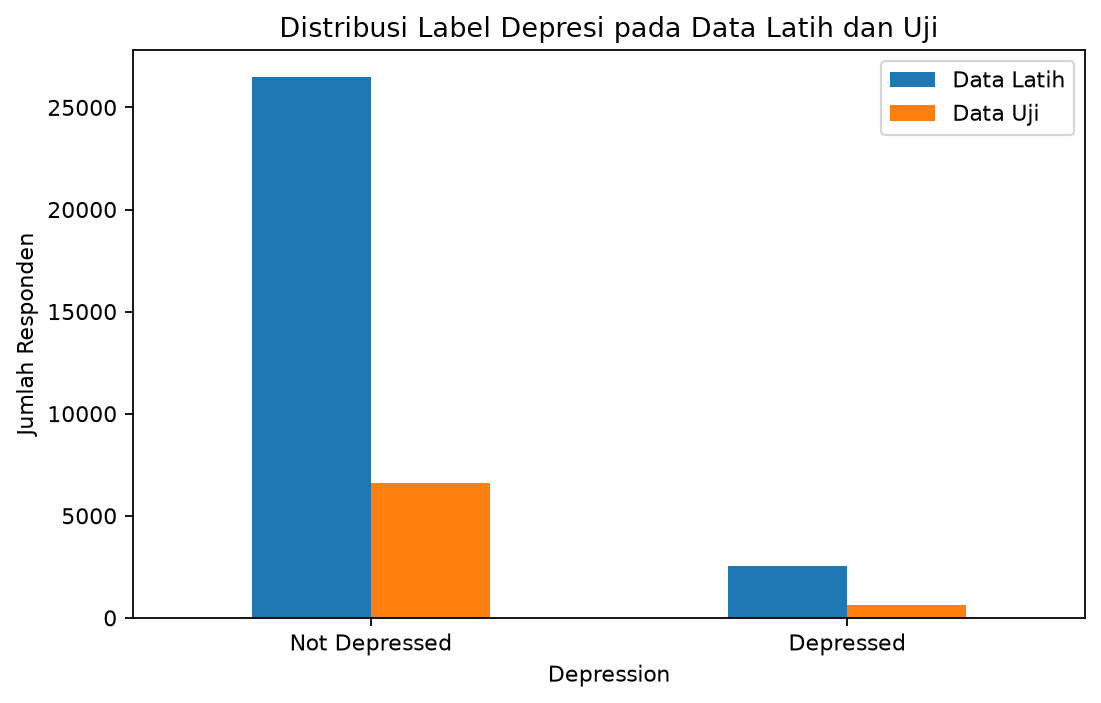

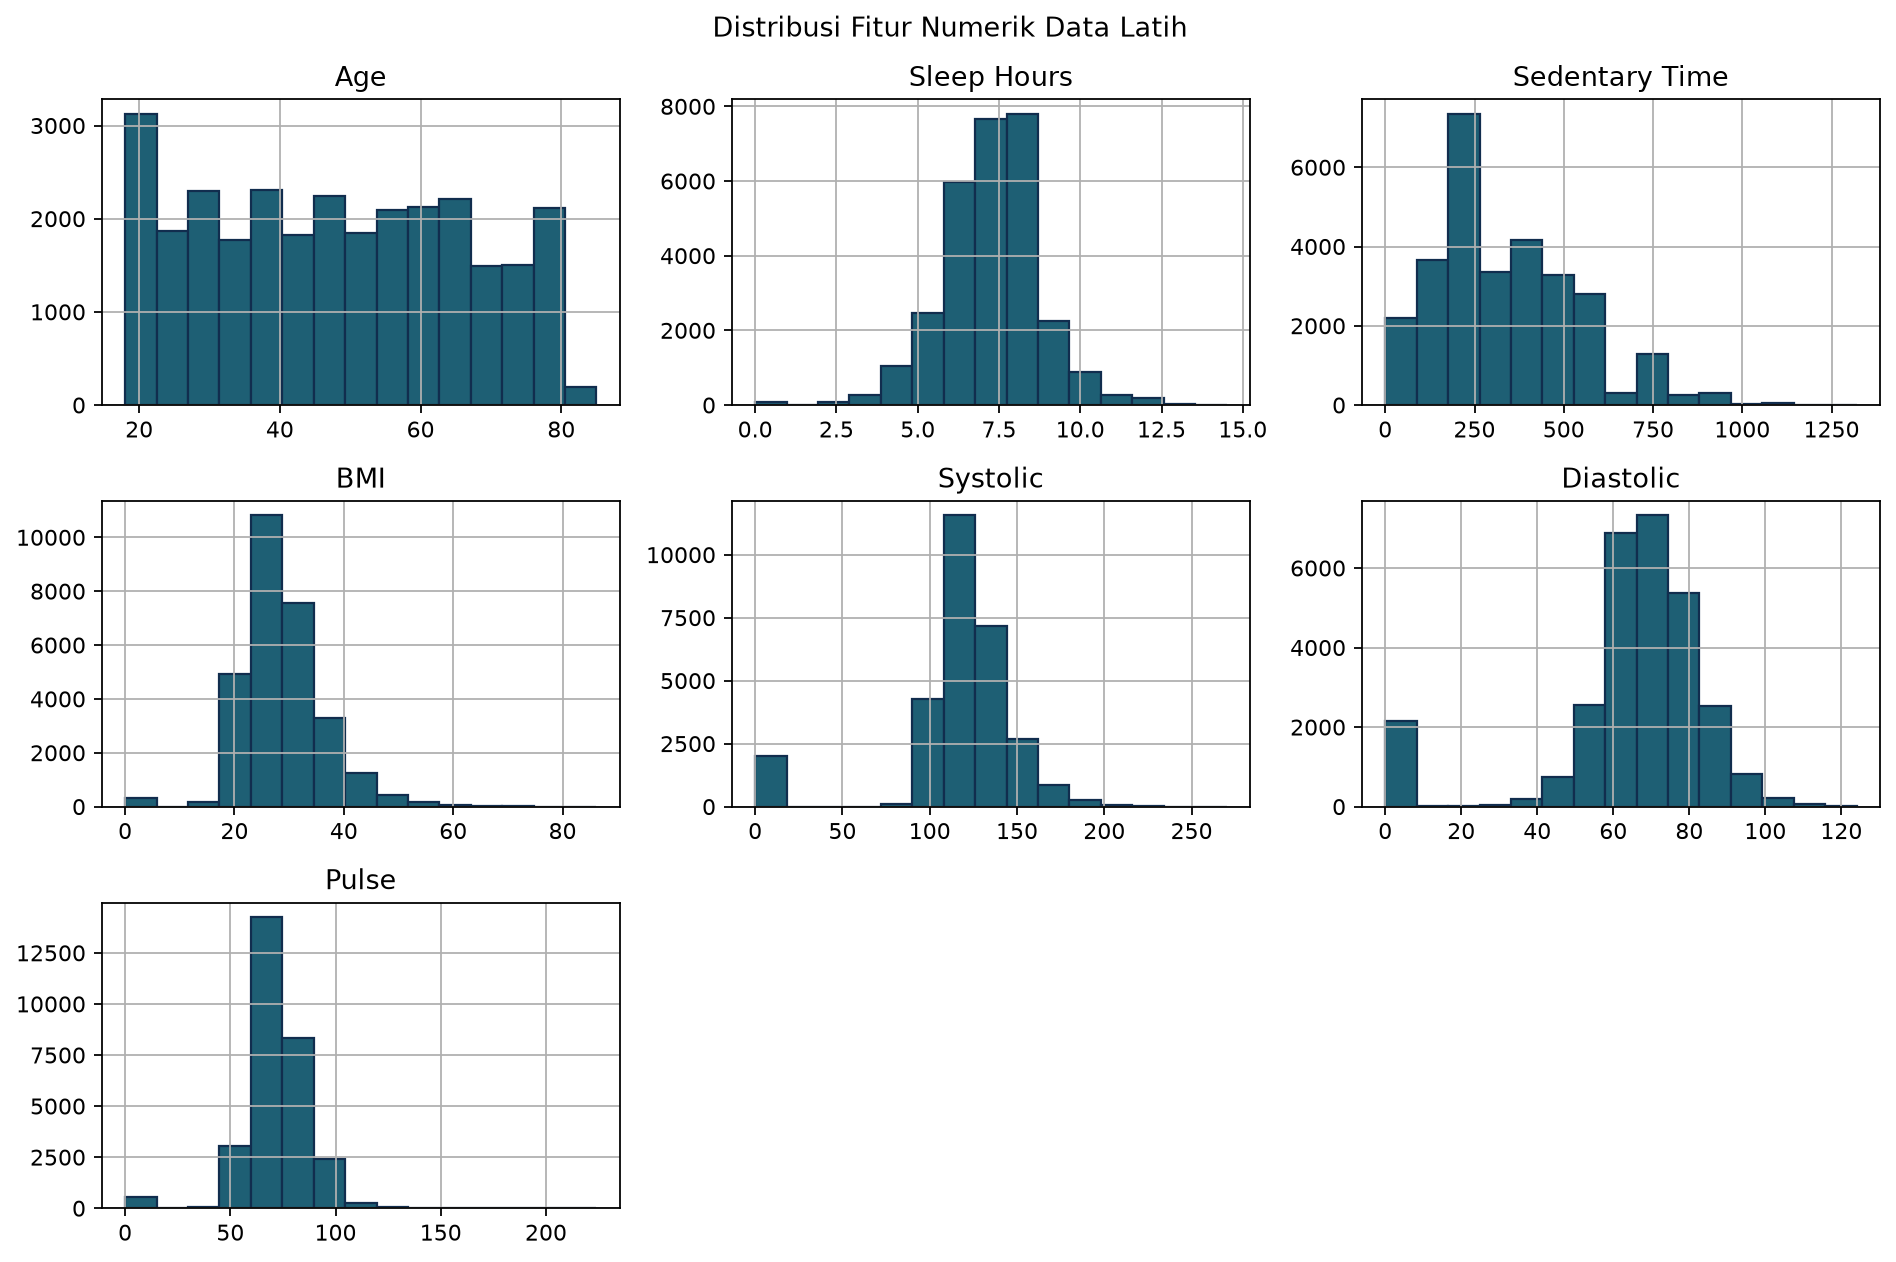

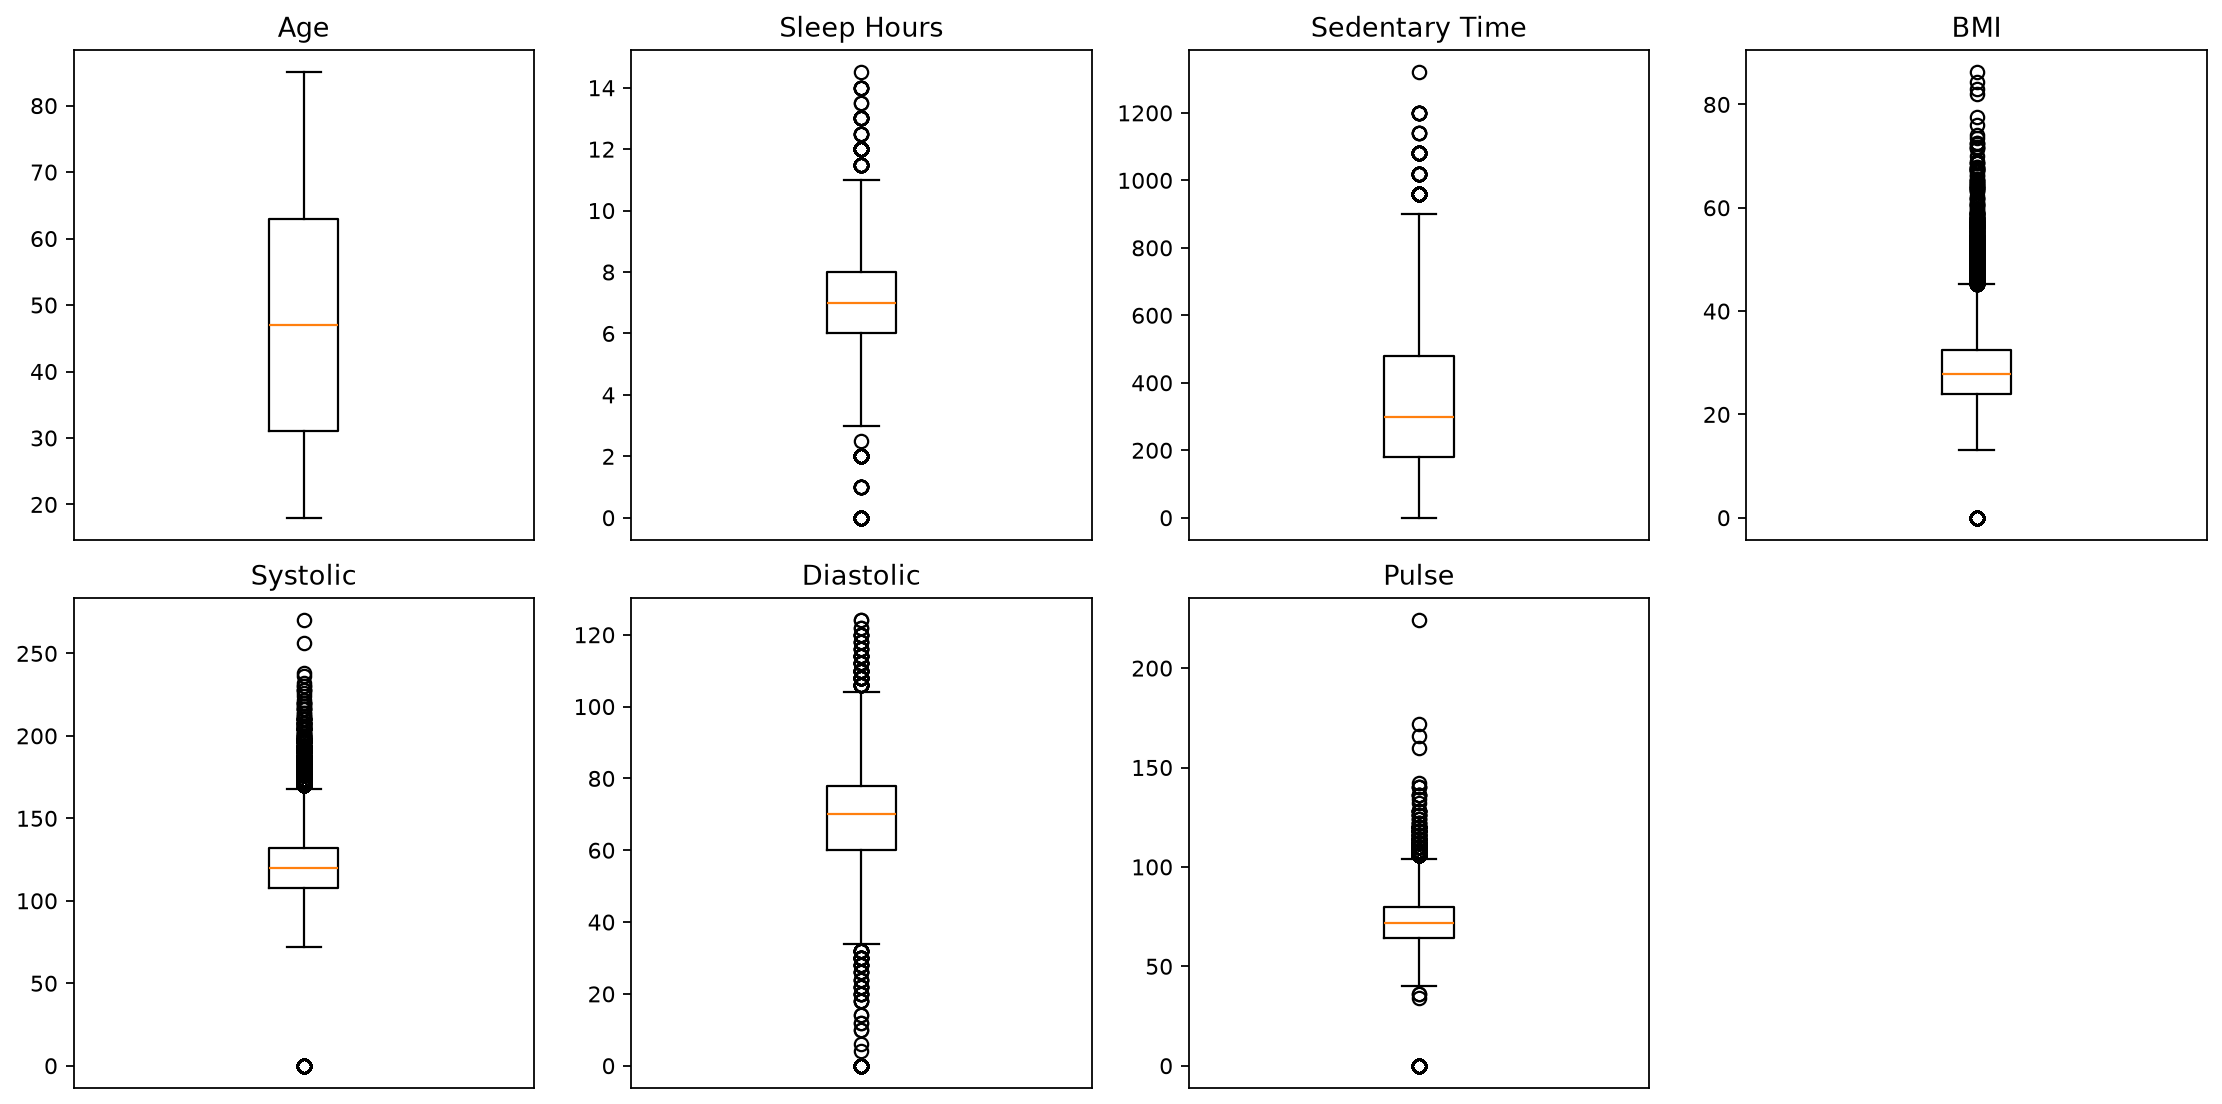

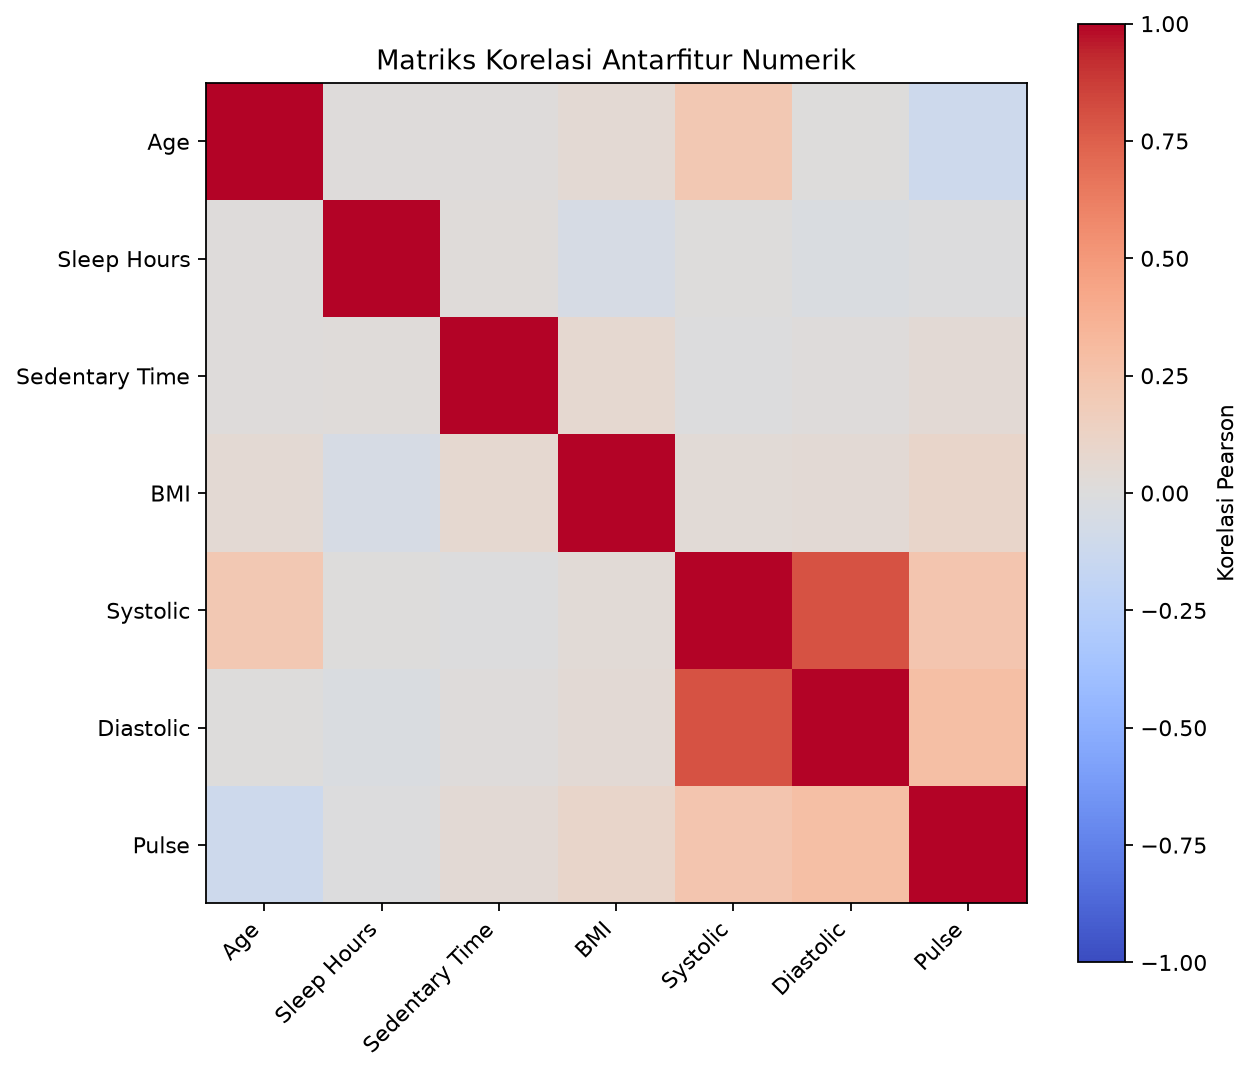

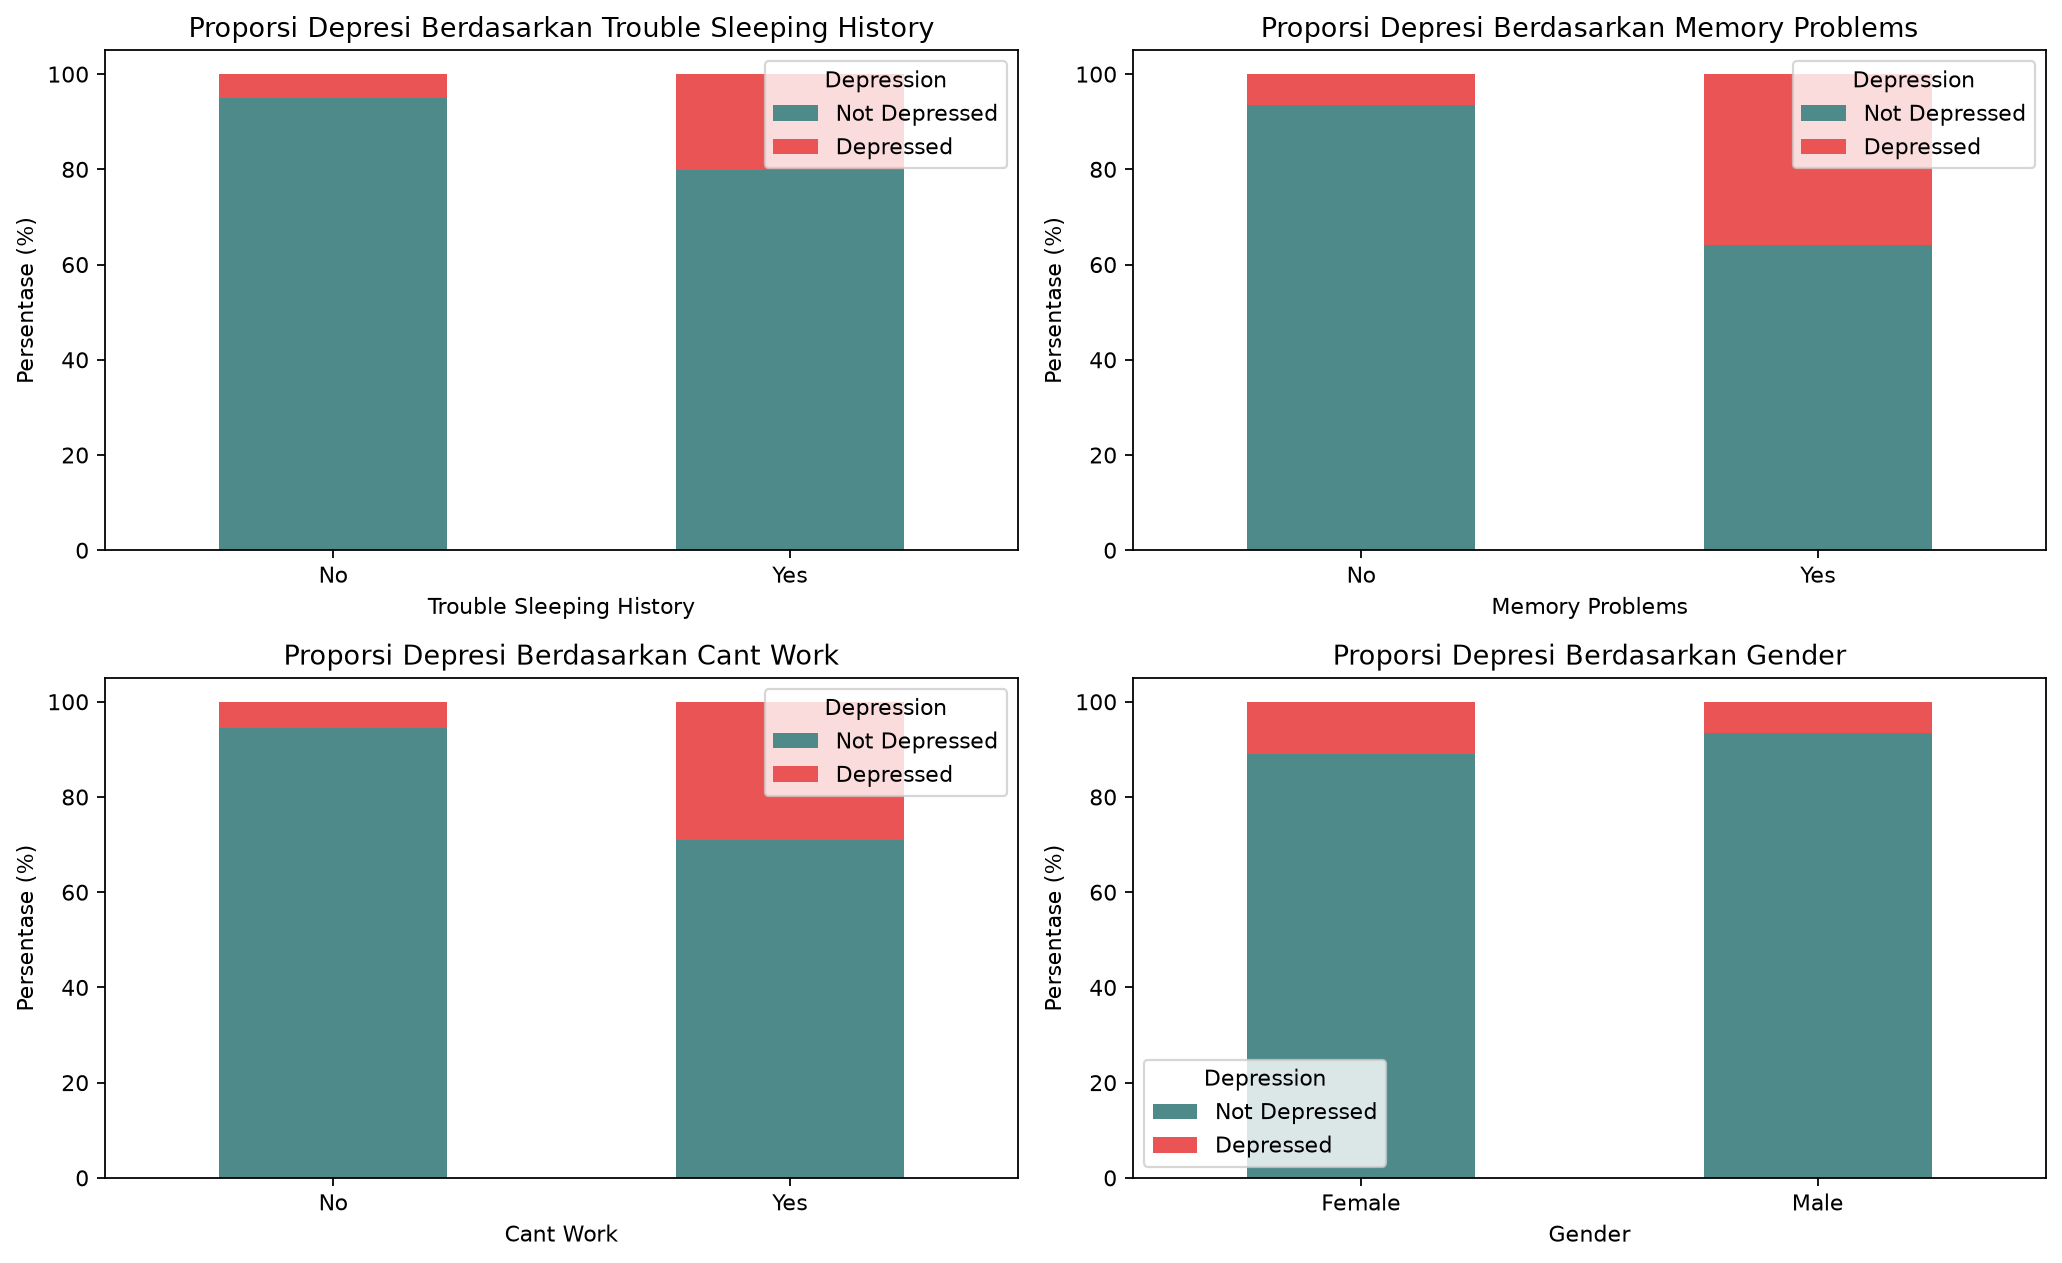

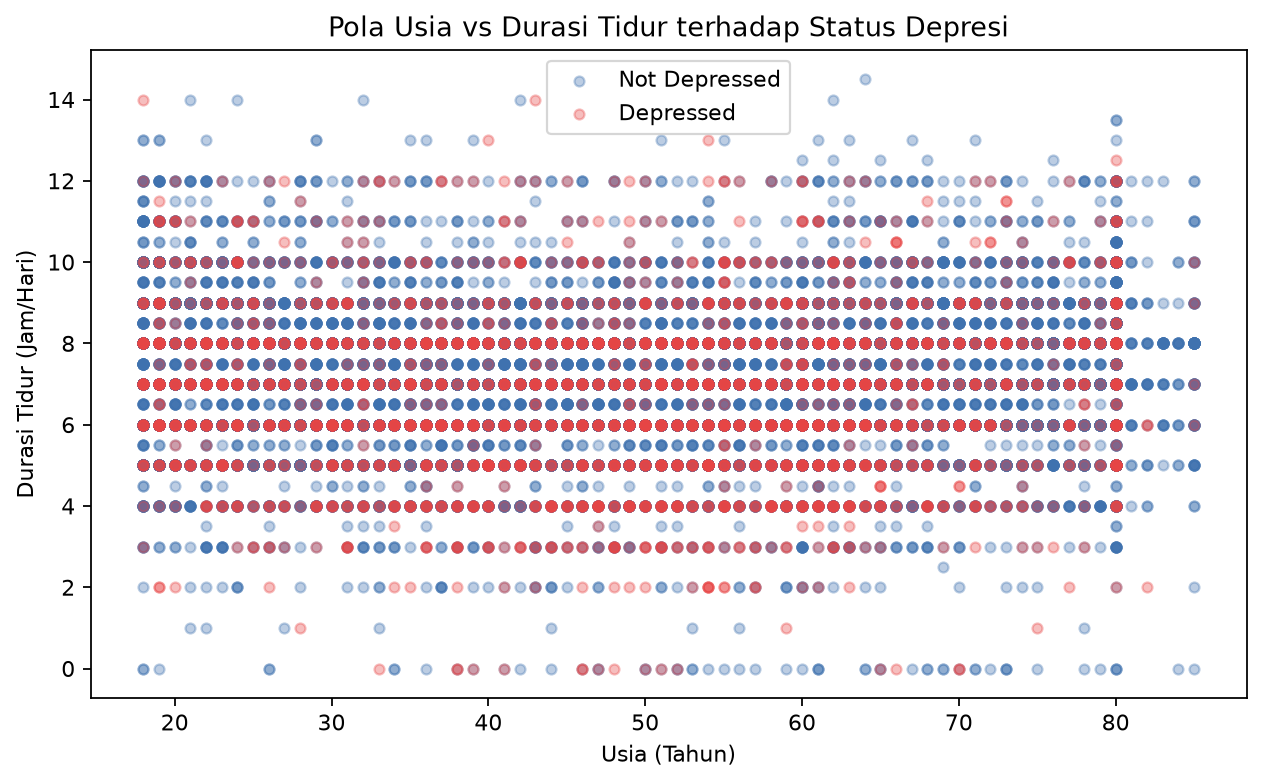

In [4]:
# 1. Distribusi Kelas
plt.figure(figsize=(7, 4.5))
pd.DataFrame({"Data Latih": y_train.value_counts(), "Data Uji": y_test.value_counts()}).reindex(LABELS).plot.bar(ax=plt.gca(), rot=0)
plt.ylabel("Jumlah Responden")
plt.title("Distribusi Label Depresi pada Data Latih dan Uji")
save_figure(EDA / "01_distribusi_kelas.png")

# 2. Histogram Numerik
X_train[NUMERIC].hist(figsize=(12, 8), bins=15, color="#1e5f74", edgecolor="#112d4e")
plt.suptitle("Distribusi Fitur Numerik Data Latih")
save_figure(EDA / "02_histogram_train.png")

# 3. Boxplot Outlier
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, col in zip(axes.flat, NUMERIC):
    ax.boxplot(X_train[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])
if len(NUMERIC) < len(axes.flat):
    for ax in axes.flat[len(NUMERIC):]:
        ax.axis("off")
save_figure(EDA / "03_boxplot_train.png")

# 4. Korelasi Matriks
correlation = X_train[NUMERIC].corr()
correlation.to_csv(EDA / "correlation_train.csv")
plt.figure(figsize=(8, 7))
plt.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
plt.xticks(range(len(NUMERIC)), NUMERIC, rotation=45, ha="right")
plt.yticks(range(len(NUMERIC)), NUMERIC)
plt.colorbar(label="Korelasi Pearson")
plt.title("Matriks Korelasi Antarfitur Numerik")
save_figure(EDA / "04_korelasi_train.png")

# 5. Visualisasi Fitur Kategorikal Kunci
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
key_cats = ["Trouble Sleeping History", "Memory Problems", "Cant Work", "Gender"]
for ax, col in zip(axes.flat, key_cats):
    counts = pd.crosstab(X_train[col], y_train, normalize="index") * 100
    counts.reindex(columns=LABELS).plot.bar(stacked=True, ax=ax, rot=0, color=["#4f8a8b", "#ea5455"])
    ax.set_title(f"Proporsi Depresi Berdasarkan {col}")
    ax.set_ylabel("Persentase (%)")
save_figure(EDA / "05_kategorikal_train.png")

# 6. Scatter Plot Hubungan Usia vs Durasi Tidur
plt.figure(figsize=(8, 5))
for label, color in [("Not Depressed", "#3f72af"), ("Depressed", "#e84545")]:
    sub = X_train.loc[y_train == label]
    plt.scatter(sub["Age"], sub["Sleep Hours"], label=label, alpha=0.35, s=20, c=color)
plt.xlabel("Usia (Tahun)")
plt.ylabel("Durasi Tidur (Jam/Hari)")
plt.title("Pola Usia vs Durasi Tidur terhadap Status Depresi")
plt.legend()
save_figure(EDA / "06_scatter_train.png")
